# MVP: full handwritten page → English text

Pipeline: **JPG/PNG page → Kraken BLLA line segmentation → TrOCR → TXT**.

BLLA finds baselines and text-line regions on the whole page. TrOCR then recognizes every extracted line.


In [17]:
import sys
from pathlib import Path

import torch
from IPython.display import display
from PIL import Image, ImageDraw, ImageOps
from kraken import blla
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)


Python: /Users/fcode-kruppo/Documents/uni/adv_soft/ex1_knn/venv_kraken/bin/python
PyTorch: 2.14.0


## 1. Input page

`INPUT_IMAGE` can point to an arbitrary full page; it does not need to be split into lines.


Input: english_page_test.png, size: (2102, 1521)


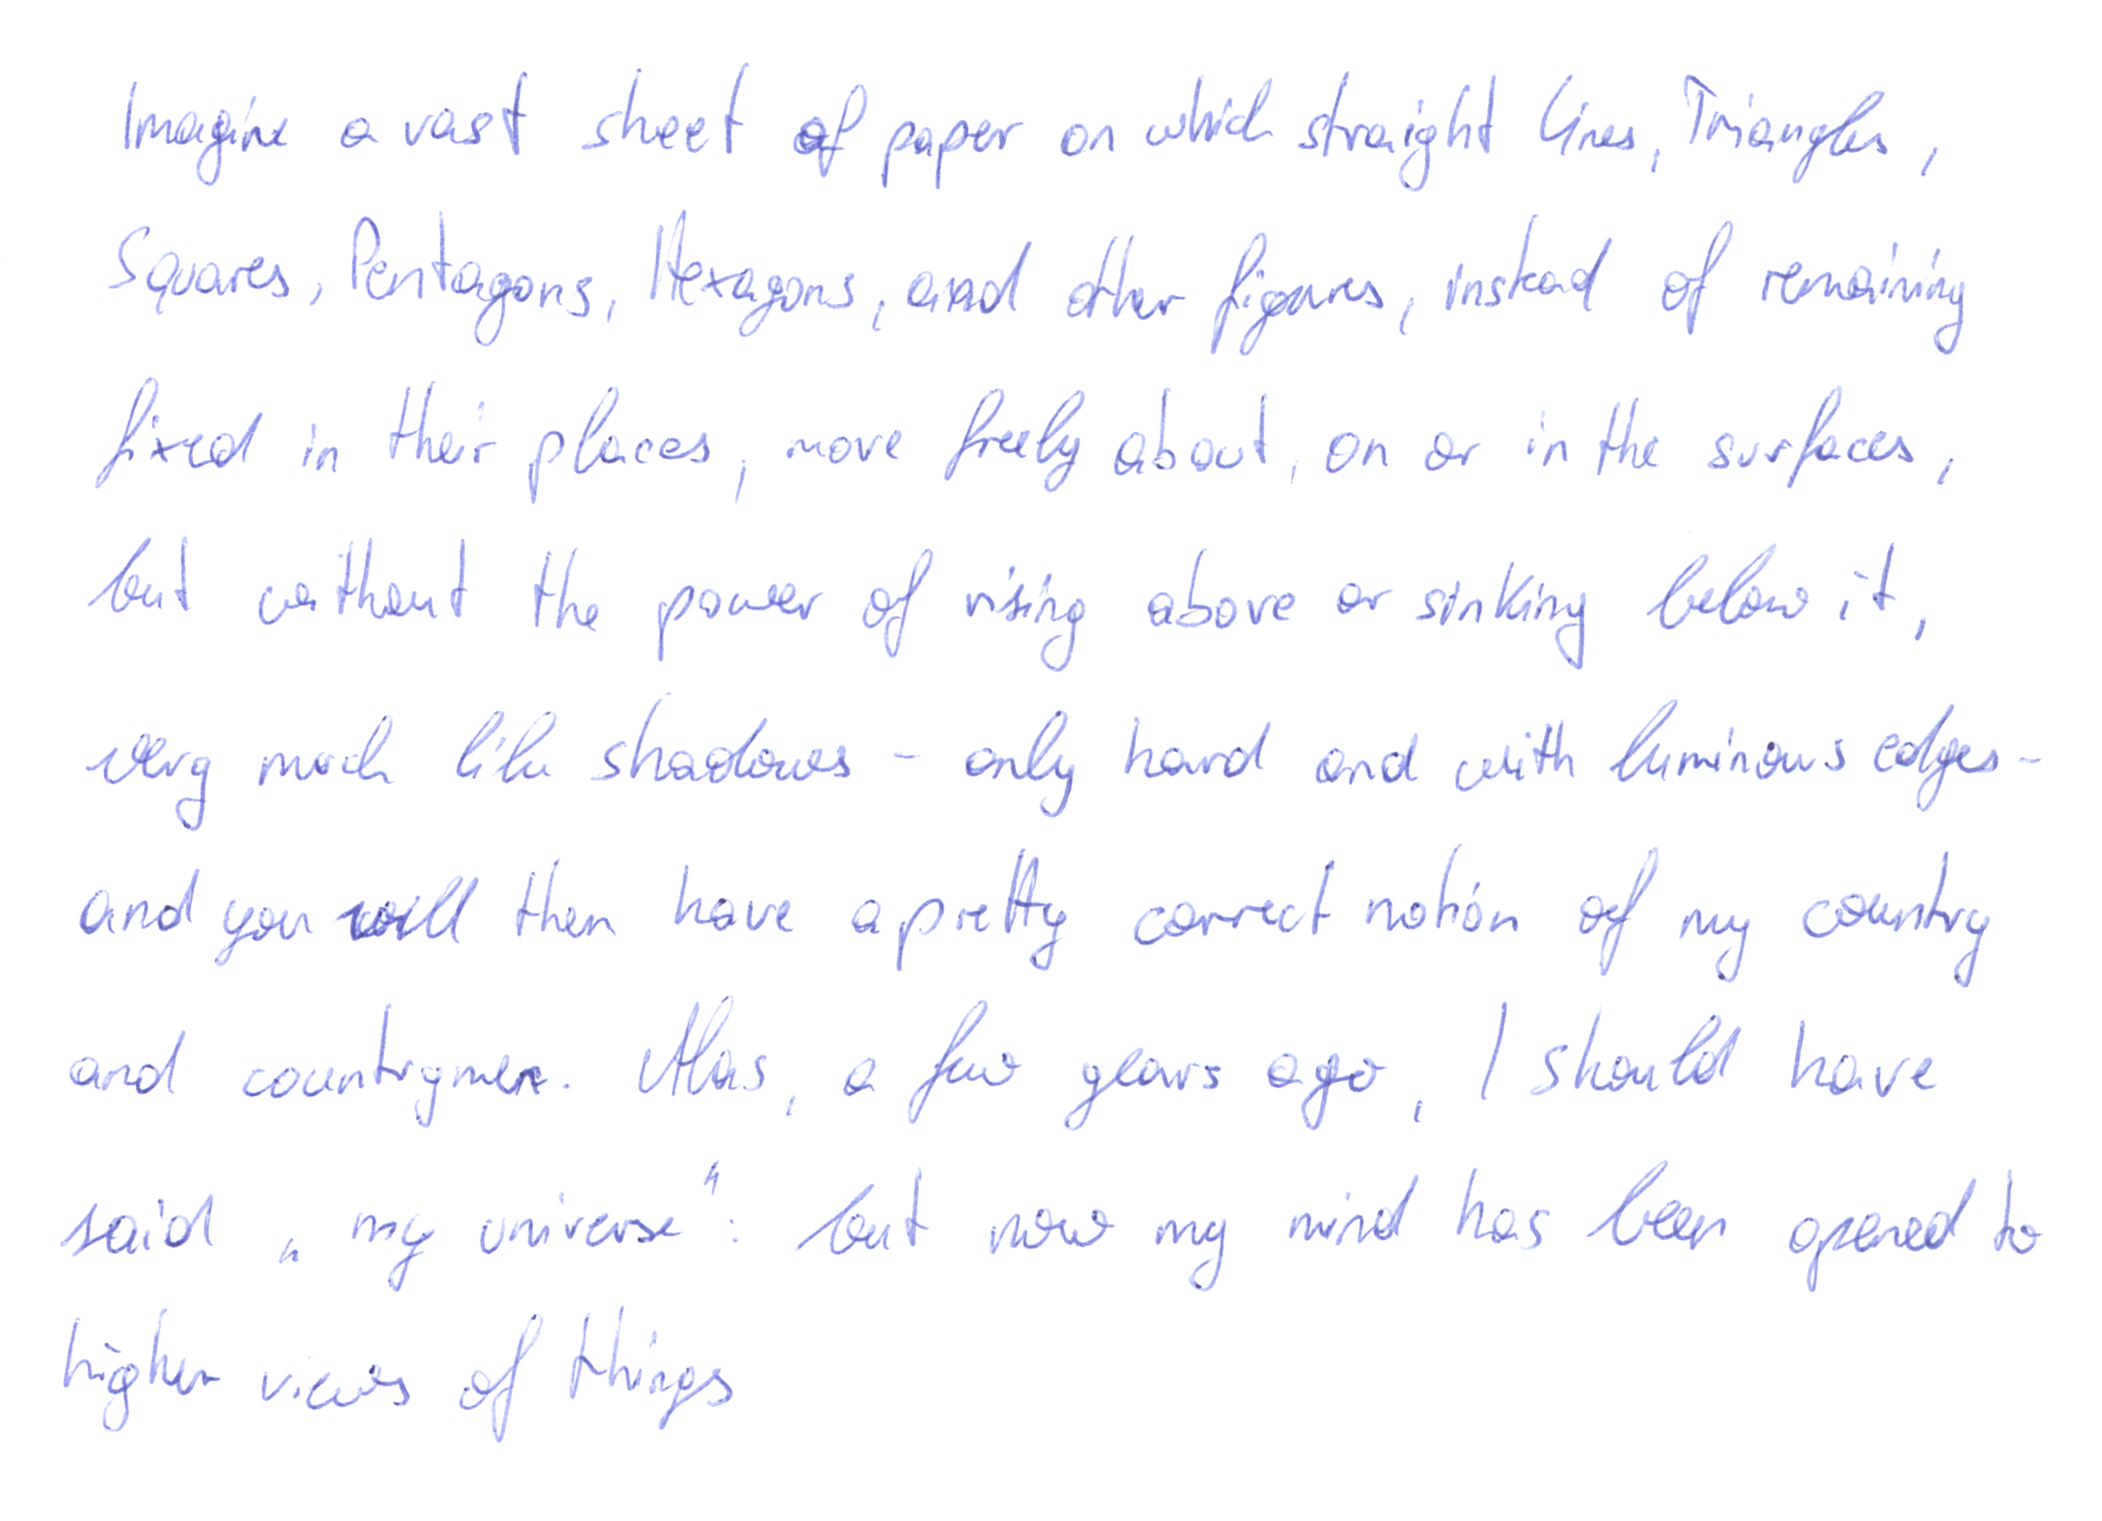

In [18]:
PROJECT_DIR = Path("/Users/fcode-kruppo/Documents/uni/adv_soft/ex1_knn")
INPUT_IMAGE = PROJECT_DIR / "english_page_test.png"
OUTPUT_TEXT = PROJECT_DIR / "english_transcription.txt"
MODEL_NAME = "microsoft/trocr-small-handwritten"

if not INPUT_IMAGE.exists():
    raise FileNotFoundError(f"Image not found: {INPUT_IMAGE}")

page = Image.open(INPUT_IMAGE).convert("RGB")
print(f"Input: {INPUT_IMAGE.name}, size: {page.size}")
display(page)


## 2. Segment the full page with Kraken BLLA

The default pretrained BLLA model is included with Kraken. It detects baselines and polygonal line regions. On light cursive it can split one visual line into several fragments, so fragments with nearly equal baseline height are merged before recognition.


/Users/fcode-kruppo/Documents/uni/adv_soft/ex1_knn/venv_kraken/lib/python3.11/site-packages/coremltools/models/model.py:628: RuntimeWarning: You will not be able to run predict() on this Core ML model. Underlying exception message was: Error compiling model: "compiler error: Error reading protobuf spec. validator error: Input MLMultiArray to neural networks must have dimension 1 (vector) or 3 (image-like arrays).".
  _warnings.warn(


BLLA fragments: 21
Merged text lines: 9


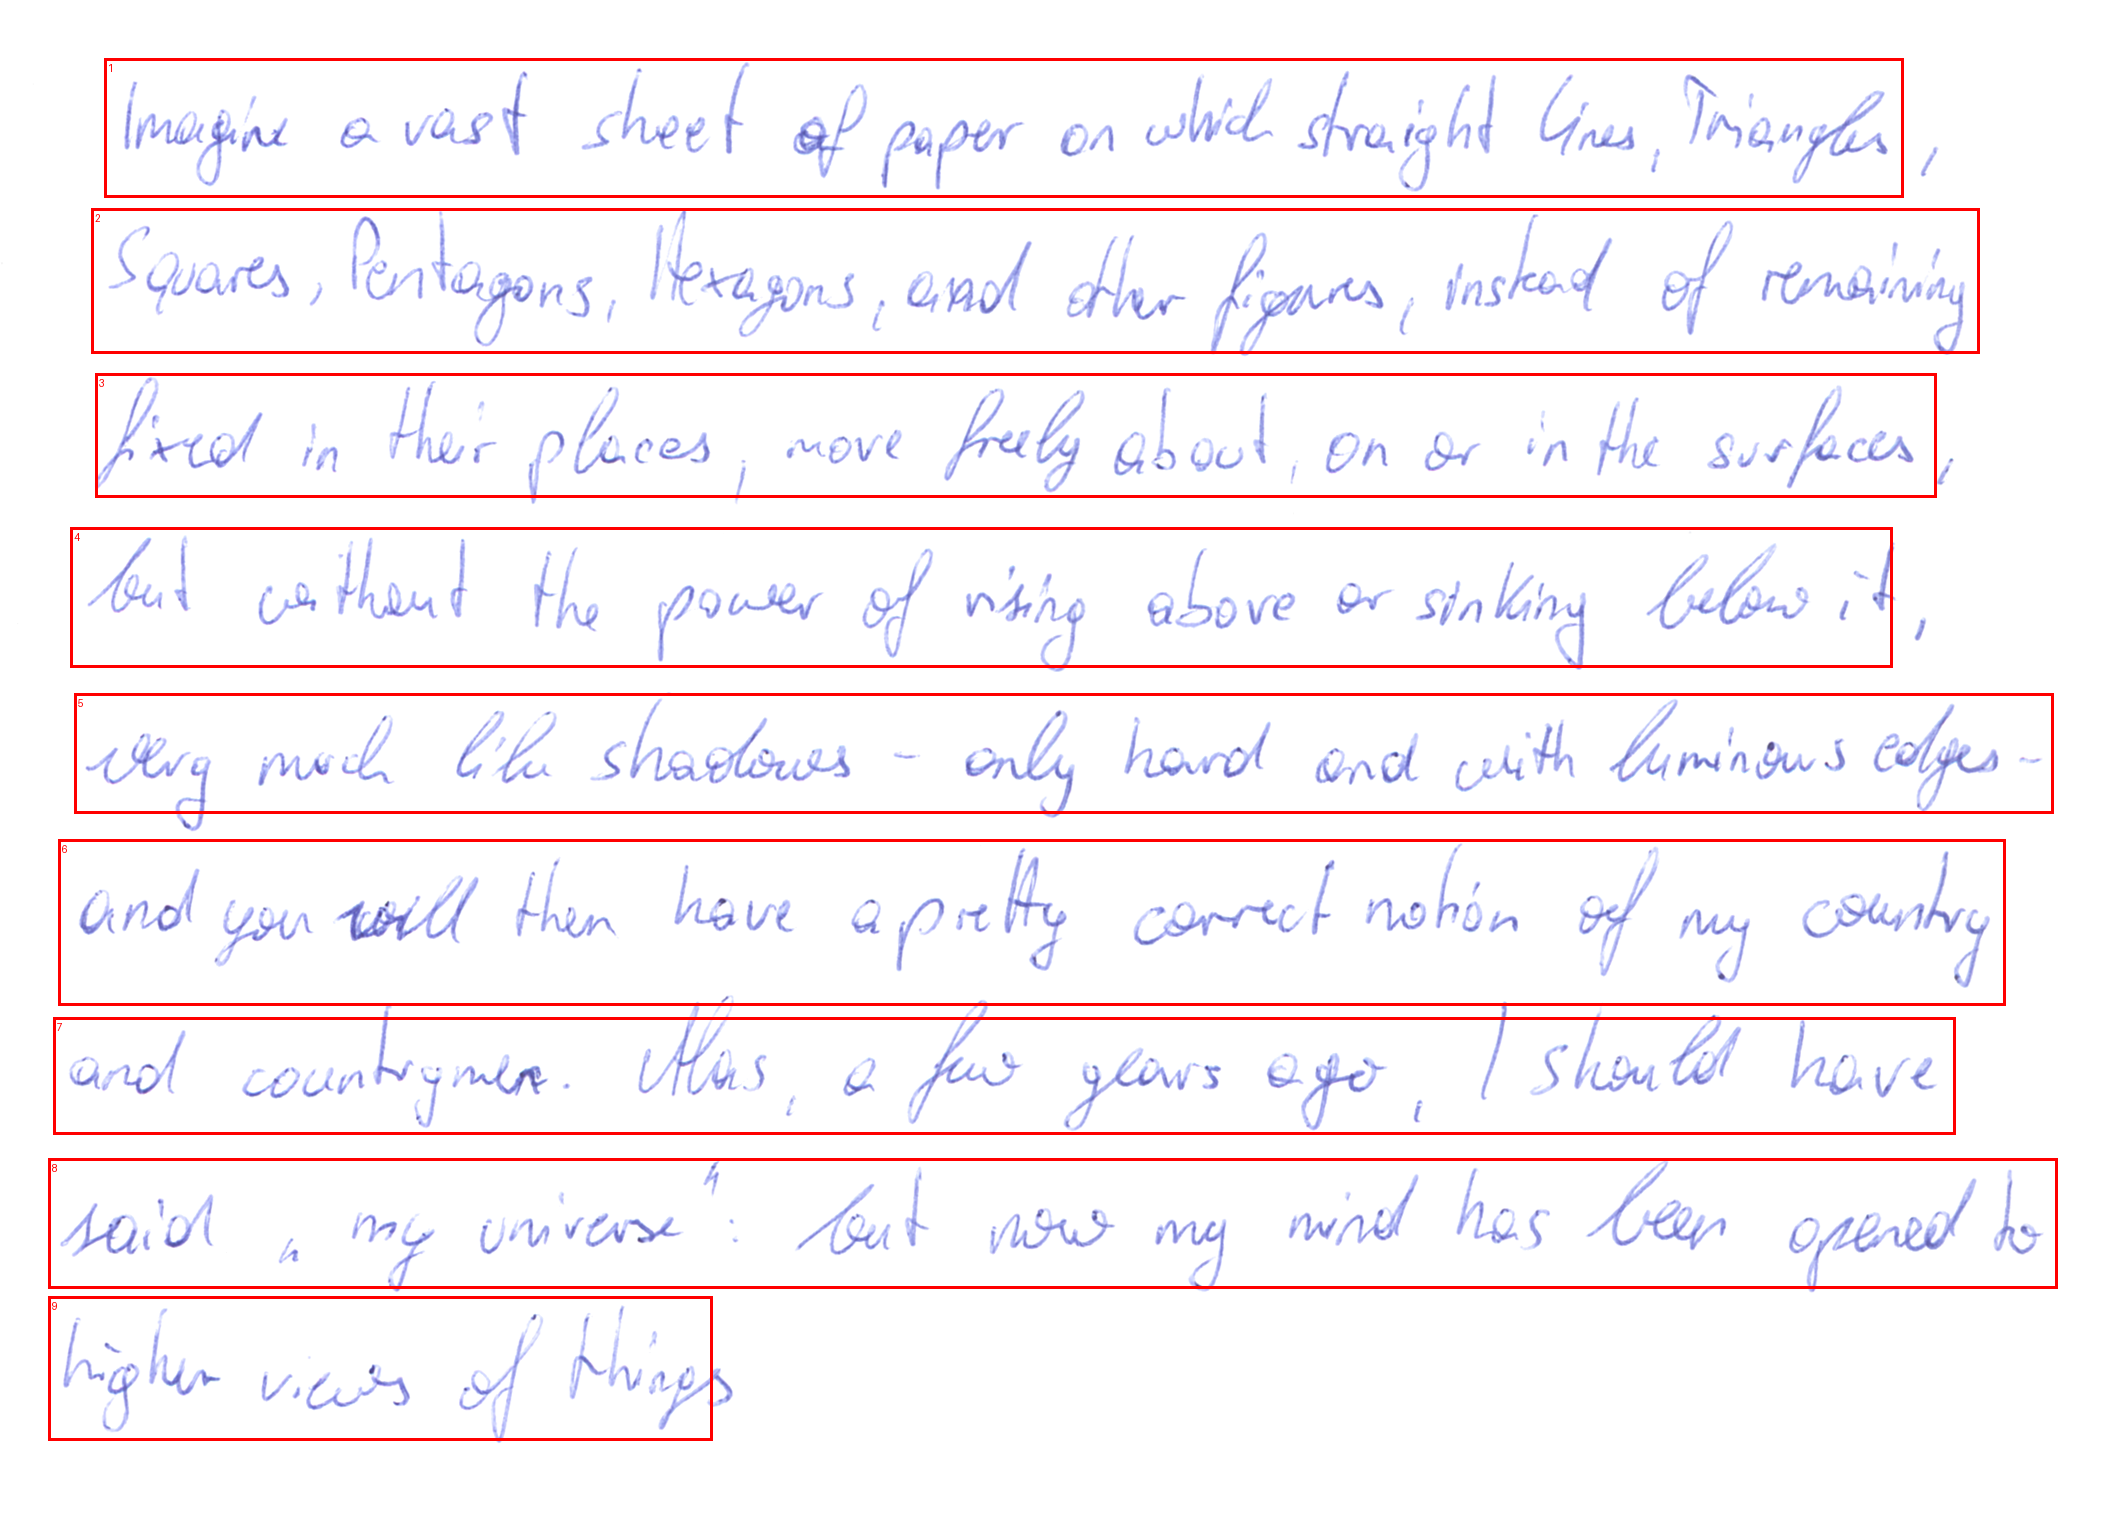

Line 1: (1799, 139)


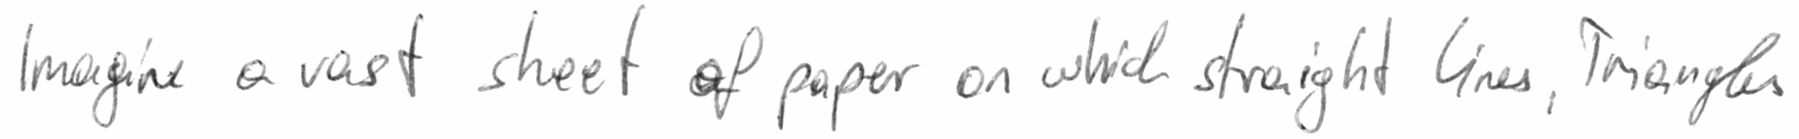

Line 2: (1888, 145)


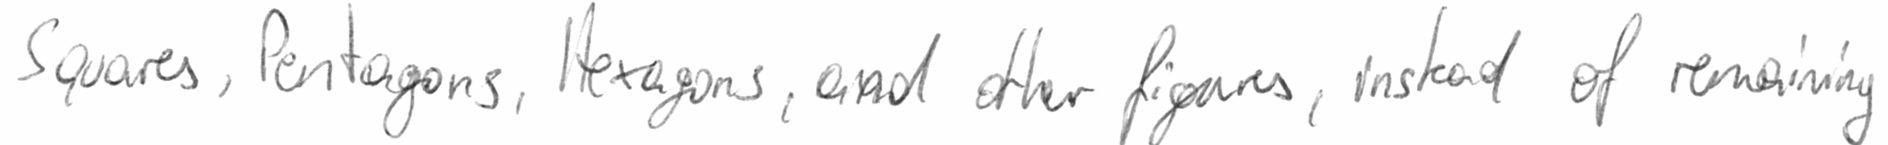

Line 3: (1841, 124)


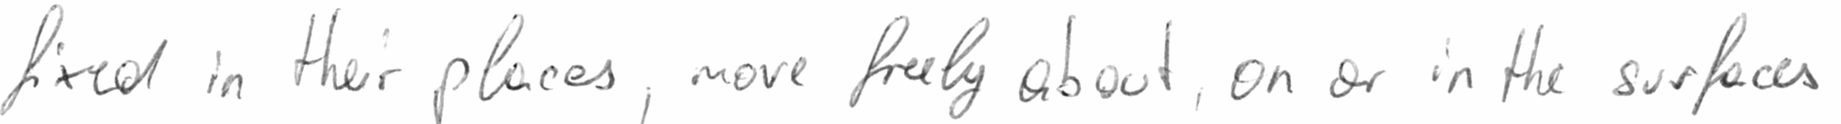

Line 4: (1822, 140)


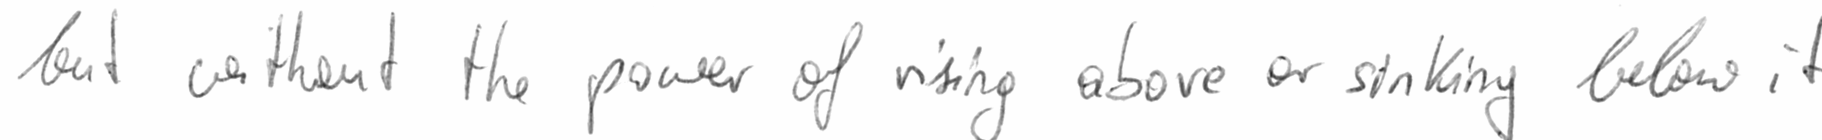

Line 5: (1979, 120)


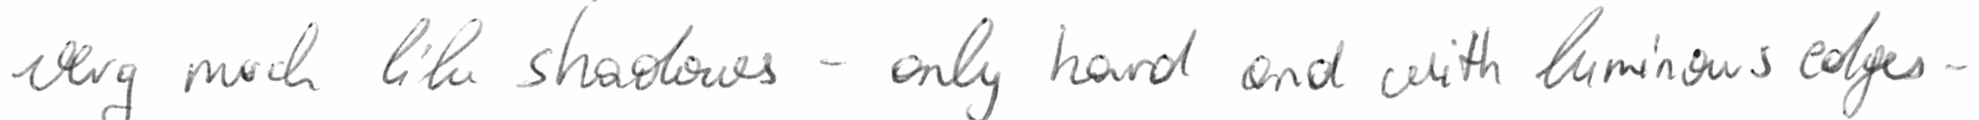

Line 6: (1947, 166)


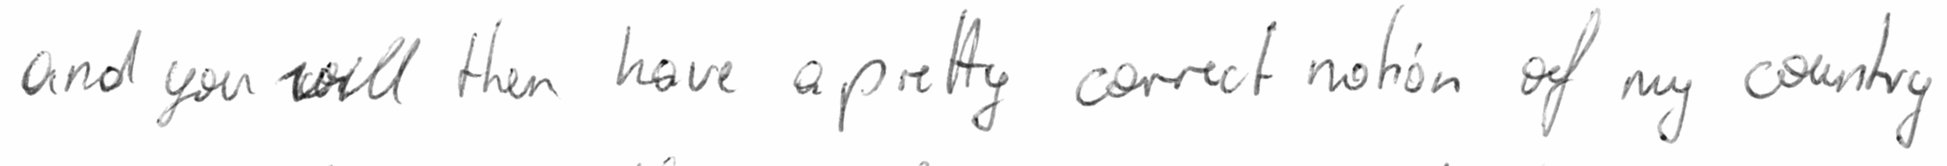

Line 7: (1902, 117)


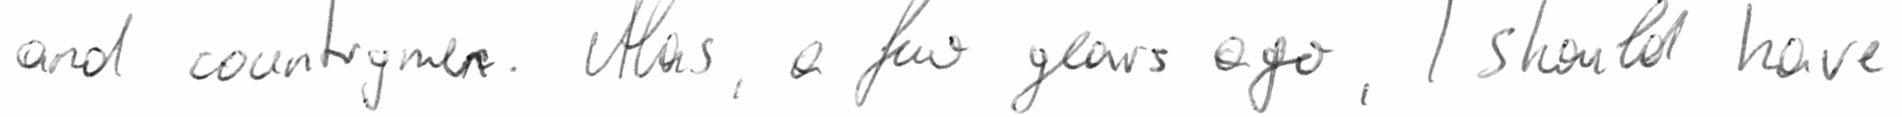

Line 8: (2009, 130)


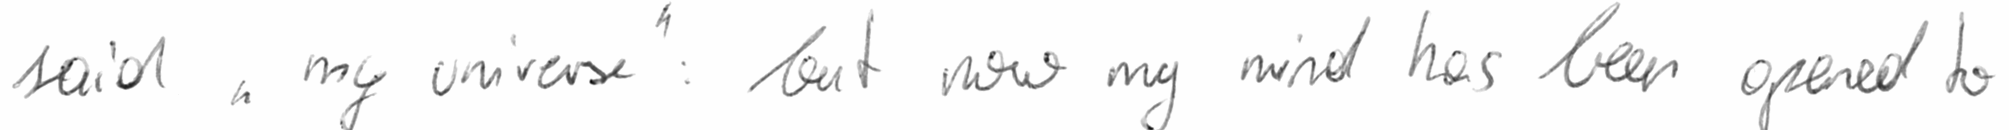

Line 9: (664, 144)


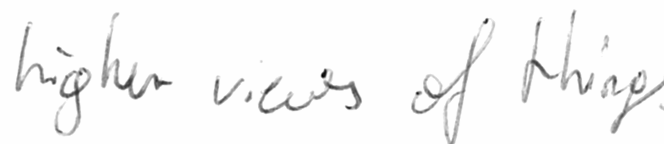

In [19]:
def baseline_y(line):
    return sum(point[1] for point in line.baseline) / len(line.baseline)


def group_blla_fragments(lines, y_tolerance=60):
    # BLLA sometimes returns left/right pieces of the same handwritten line.
    groups = []
    for line in sorted(lines, key=baseline_y):
        y = baseline_y(line)
        if groups and abs(y - groups[-1]["mean_y"]) <= y_tolerance:
            groups[-1]["lines"].append(line)
            values = [baseline_y(item) for item in groups[-1]["lines"]]
            groups[-1]["mean_y"] = sum(values) / len(values)
        else:
            groups.append({"mean_y": y, "lines": [line]})
    return groups


def segment_page_with_blla(image, y_tolerance=60, padding=12):
    # Stronger contrast helps BLLA and TrOCR with pale blue handwriting.
    prepared = ImageOps.autocontrast(ImageOps.grayscale(image)).convert("RGB")
    segmentation = blla.segment(prepared, text_direction="horizontal-lr", device="cpu")
    groups = group_blla_fragments(segmentation.lines, y_tolerance=y_tolerance)

    crops = []
    boxes = []
    for group in groups:
        points = [point for line in group["lines"] for point in line.boundary]
        left = max(0, int(min(p[0] for p in points)) - padding)
        top = max(0, int(min(p[1] for p in points)) - padding)
        right = min(prepared.width, int(max(p[0] for p in points)) + padding + 1)
        bottom = min(prepared.height, int(max(p[1] for p in points)) + padding + 1)
        boxes.append((left, top, right, bottom))
        crops.append(prepared.crop((left, top, right, bottom)))

    if not crops:
        raise RuntimeError("BLLA did not find any text lines.")
    return segmentation, crops, boxes


segmentation, line_images, line_boxes = segment_page_with_blla(page)
print(f"BLLA fragments: {len(segmentation.lines)}")
print(f"Merged text lines: {len(line_images)}")

overlay = page.copy()
draw = ImageDraw.Draw(overlay)
for number, box in enumerate(line_boxes, start=1):
    draw.rectangle(box, outline="red", width=3)
    draw.text((box[0] + 4, box[1] + 4), str(number), fill="red")
display(overlay)

for number, line in enumerate(line_images, start=1):
    print(f"Line {number}: {line.size}")
    display(line)


## 3. Load pretrained English handwriting model

`microsoft/trocr-small-handwritten` was fine-tuned on English IAM handwriting. It is a line recognizer, while BLLA handles the page segmentation. The model downloads on the first run and is then cached locally.


In [20]:
DEVICE = "cpu"
processor = TrOCRProcessor.from_pretrained(MODEL_NAME)
model = VisionEncoderDecoderModel.from_pretrained(MODEL_NAME).to(DEVICE)
model.eval()
print(f"Loaded {MODEL_NAME} on {DEVICE}")


Some weights of VisionEncoderDecoderModel were not initialized from the model checkpoint at microsoft/trocr-small-handwritten and are newly initialized: ['encoder.pooler.dense.bias', 'encoder.pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Loaded microsoft/trocr-small-handwritten on cpu


## 4. Transcribe lines and save TXT


In [21]:
def transcribe_lines(images, batch_size=4):
    results = []
    for start in range(0, len(images), batch_size):
        batch = images[start:start + batch_size]
        pixel_values = processor(images=batch, return_tensors="pt").pixel_values.to(DEVICE)
        with torch.inference_mode():
            generated_ids = model.generate(
                pixel_values, max_new_tokens=128, num_beams=4
            )
        texts = processor.batch_decode(generated_ids, skip_special_tokens=True)
        results.extend(text.strip() for text in texts)
    return results


recognized_lines = transcribe_lines(line_images)
recognized_text = "\n".join(recognized_lines)
OUTPUT_TEXT.write_text(recognized_text, encoding="utf-8")

print(recognized_text)
print(f"\nSaved to: {OUTPUT_TEXT}")


imagine a vast sheet of paper on which straight lines , Triangle
Squares , Pentagons , Veragons , and other figures , instead of remaining
forced in their places , more freely about , on or in the surfaces
but without the power of using above or sinking below it
very much like shareholders - only heard and with luminous edges-
and you had then have a pretty correct nation of my country
and countrymen . Miss , a few years ago , I should have
said " my universe : ' but now my mind has been opened to
higher views of things

Saved to: /Users/fcode-kruppo/Documents/uni/adv_soft/ex1_knn/english_transcription.txt


## What each model does

- **Kraken BLLA:** receives the whole page and finds text lines; it does not transcribe them.
- **TrOCR:** receives one extracted line at a time and returns English text.
- For new page styles, tune `y_tolerance`; for better word accuracy, fine-tune TrOCR on line images paired with exact transcriptions.
